# Can online hours rise while riders wait as long?

**Week 4, Monday, chapter 1 of 3 (L1).** On Monday 31 August 2026 the Uber city team in
Hyderabad launched a peak-hour earnings guarantee: a floor of Rs 300 per peak online hour,
with Uber paying the gap between trip earnings and the floor as a top-up. Six weeks later,
peak online hours were up 24 percent and completed peak trips up 3 percent, so trips per
peak online hour fell from 1.90 to 1.58. This notebook counts six drivers in two particular
weeks by hand, before any groupby runs.

> *Illustrative case: the company is real, the situation and the data are synthetic, built
> for this class.*

**Who needs the answer.** The city head, before Friday. Driver operations, who sign off on
supply. Finance, who hold the top-up budget. **The questions on the way.**

1. What did the six drivers' hours and trips do between the two weeks?
2. What is trips per peak online hour, before and after, on the twelve rows?
3. Which drivers moved the ratio most, and in which direction?

**Setup.** The first cell finds the shared helper `c2kit` and loads the three case CSVs
from `../data/`. Every number below comes from those files or from the day's facts file;
nothing is typed in. Run this cell again after any kernel restart.

In [1]:
import sys, pathlib
here = pathlib.Path.cwd()
for parent in [here, *here.parents]:
    if (parent / "scripts" / "c2kit.py").exists():
        sys.path.insert(0, str(parent / "scripts")); break
import c2kit as kit

import pandas as pd
drivers = pd.read_csv("../data/C2_W04_D01_drivers_STUDENT.csv")
dw = pd.read_csv("../data/C2_W04_D01_driver_weeks_STUDENT.csv")
zones = pd.read_csv("../data/C2_W04_D01_zone_weeks_STUDENT.csv")
print(f"drivers: {len(drivers)}, driver_weeks: {len(dw)}, zones: {len(zones)}")

drivers: 1200, driver_weeks: 12860, zones: 144


## Where does chapter 1 sit on the day's ladder?

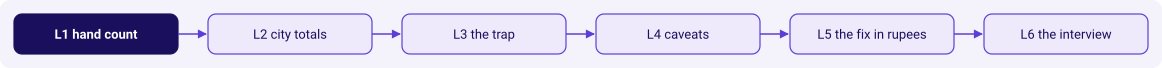

In [2]:
kit.flow(["L1 hand count", "L2 city totals", "L3 the trap",
          "L4 caveats", "L5 the fix in rupees", "L6 the interview"], lit=0)

## What are the twelve rows the case asks us to read first?

The twelve rows are six drivers (A to F), each in two particular weeks: the week beginning
10 August 2026 (before the launch) and the week beginning 21 September 2026 (after). Drivers
A to D live in core zones (Jubilee Hills, Banjara Hills, Gachibowli, Madhapur). Drivers E
and F live in outer zones (Shamshabad, Rajendranagar). Each row prints hours, offers,
accepted, cancels and trips. `driver_weeks` counts offers, every time a request was shown to a
driver, and a request one driver declines is offered to the next, so offers outnumber the rider
requests that `zone_weeks` counts.

In [3]:
twelve_ids = {"d_0001": "A", "d_0002": "B", "d_0003": "C", "d_0004": "D",
               "d_0881": "E", "d_0882": "F"}
twelve = dw[(dw["driver_id"].isin(twelve_ids))
            & (dw["week_start"].isin(["2026-08-10", "2026-09-21"]))].copy()
twelve["driver"] = twelve["driver_id"].map(twelve_ids)
twelve["when"] = twelve["week_start"].map({"2026-08-10": "before", "2026-09-21": "after"})
twelve = twelve.sort_values(["driver", "when"])[
    ["driver", "when", "zone_mode", "peak_online_hours",
     "peak_offers", "peak_accepted", "peak_driver_cancels", "peak_trips"]
].reset_index(drop=True)
twelve

,driver,when,zone_mode,peak_online_hours,peak_offers,peak_accepted,peak_driver_cancels,peak_trips
0,A,after,Jubilee Hills,11,25,22,0,22
1,A,before,Jubilee Hills,10,24,21,0,21
2,B,after,Banjara Hills,10,21,18,0,18
3,B,before,Banjara Hills,9,20,17,0,17
4,C,after,Gachibowli,12,26,23,0,23
5,C,before,Gachibowli,11,25,22,0,22
6,D,after,Madhapur,11,23,20,0,20
7,D,before,Madhapur,10,22,19,0,19
8,E,after,Shamshabad,16,14,4,1,3
9,E,before,Shamshabad,10,21,18,0,18


**What happened.** Row by row: A, B, C, D add about one hour and one trip from before to
after; their rate stays near 2 trips per hour. E jumps from 10 hours and 18 trips to 16
hours and 3 trips. F jumps from 10 hours and 17 trips to 14 hours and 2 trips. E and F are
two drivers in outer zones whose hours rose and whose trips did not follow.

## What are the four totals a hand count reaches?

A rate as a ratio of two sums, never the mean of per-driver ratios: `sum(trips) /
sum(hours)`. The denominator says what the number is per.

In [4]:
before = twelve[twelve["when"] == "before"]
after = twelve[twelve["when"] == "after"]
totals = pd.DataFrame({
    "window": ["before", "after"],
    "hours":  [before["peak_online_hours"].sum(), after["peak_online_hours"].sum()],
    "trips":  [before["peak_trips"].sum(), after["peak_trips"].sum()],
})
totals["trips_per_hour"] = (totals["trips"] / totals["hours"]).round(3)
totals

,window,hours,trips,trips_per_hour
0,before,60,114,1.900
1,after,74,88,1.189


**The ratio on twelve rows.** Hours 60 to 74 (up 23 percent). Trips 114 to 88 (down 23
percent). Trips per peak online hour 1.90 to 1.19. The twelve rows show a sharper paradox
than the city will show on the full data: here, hours up means trips per hour nearly
halved.

## Which drivers moved the ratio most, and in which direction?

**Predict first.** Among the six drivers, which two moved the per-driver trips per hour the
most between the two weeks, in absolute value? Letters:

- a) A and B
- b) C and D
- c) E and F
- d) The pair cannot be told without more data

In [5]:
pivot = twelve.pivot_table(index="driver", columns="when",
                           values=["peak_online_hours", "peak_trips"])
pivot.columns = [f"{a}_{b}" for a, b in pivot.columns]
pivot["tph_before"] = (pivot["peak_trips_before"] / pivot["peak_online_hours_before"]).round(2)
pivot["tph_after"] = (pivot["peak_trips_after"] / pivot["peak_online_hours_after"]).round(2)
pivot["tph_change"] = (pivot["tph_after"] - pivot["tph_before"]).round(2)
pivot[["tph_before", "tph_after", "tph_change"]].sort_values("tph_change")

,tph_before,tph_after,tph_change
driver,,,
E,1.80,0.19,-1.61
F,1.70,0.14,-1.56
A,2.10,2.00,-0.10
B,1.89,1.80,-0.09
D,1.90,1.82,-0.08
C,2.00,1.92,-0.08


**What happened.** The answer is c, drivers E and F. Their trips per peak online hour fell
to 0.19 and 0.14 (close to zero), while the others held between about 1.80 and 1.92. The
city total is pulled down by a small share of driver-weeks like these, which the next
notebook finds among 12,860 driver-weeks.

## What picture carries the twelve rows into chapter 2?

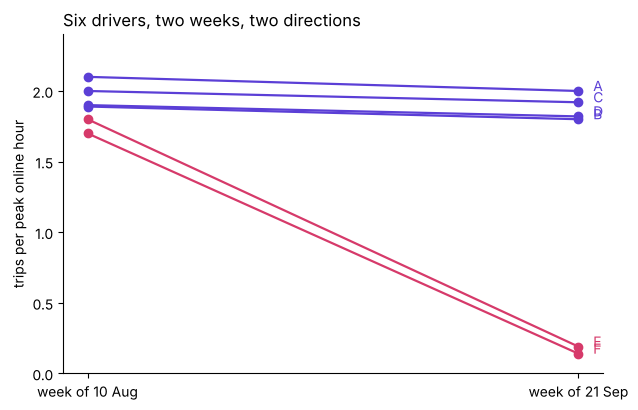

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for driver, color in zip(["A", "B", "C", "D", "E", "F"],
                          ["#5B3FD6", "#5B3FD6", "#5B3FD6", "#5B3FD6",
                           "#D63A6A", "#D63A6A"]):
    row = pivot.loc[driver]
    ax.plot([0, 1], [row["tph_before"], row["tph_after"]],
            marker="o", color=color, linewidth=1.6)
    ax.text(1.03, row["tph_after"], driver, color=color, fontsize=10)
ax.set_xticks([0, 1])
ax.set_xticklabels(["week of 10 Aug", "week of 21 Sep"])
ax.set_ylabel("trips per peak online hour")
ax.set_ylim(0, 2.4)
ax.set_title("Six drivers, two weeks, two directions", loc="left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

**What happened.** Four lines stay near 2 trips per hour. Two lines drop almost to zero.
The ratio for the whole twelve rows (sum over sum) is the picture the city sees, but the
story of the fall is in the two drivers who split off.

## What do the twelve-row totals read, side by side?

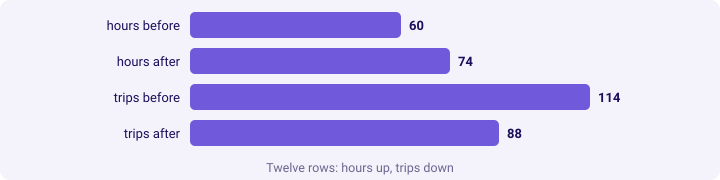

In [7]:
kit.bars([("hours before", int(totals.loc[0, "hours"])),
          ("hours after", int(totals.loc[1, "hours"])),
          ("trips before", int(totals.loc[0, "trips"])),
          ("trips after", int(totals.loc[1, "trips"]))],
         title="Twelve rows: hours up, trips down")

## What does chapter 1 close with?

In [8]:
kit.check("hand count: hours before 60", int(totals.loc[0, "hours"]) == 60)
kit.check("hand count: hours after 74", int(totals.loc[1, "hours"]) == 74)
kit.check("hand count: trips before 114", int(totals.loc[0, "trips"]) == 114)
kit.check("hand count: trips after 88", int(totals.loc[1, "trips"]) == 88)
kit.check("ratio before 1.90", float(totals.loc[0, "trips_per_hour"]) == 1.9)
kit.check("ratio after 1.19",
          abs(float(totals.loc[1, "trips_per_hour"]) - 1.189) < 0.005)

**Chapter 1 close.** Hours up 23 percent, trips down 23 percent, trips per peak online
hour nearly halved on the twelve rows. The next notebook moves from six drivers in two
weeks to 1,200 drivers over twelve weeks and asks whether the paradox holds on 12,860
driver-weeks.

> **Kavya's review.** "Six drivers is a hand count, not a result. The same question on the
> full data is the next thing to run; the paradox should be smaller in the city because
> not everyone is E or F."